# Lab 7 - Introduction to Pymunk Physics Engine
**TEB2103 Modelling and Simulation - Week 10**

---

## 1. Learning Outcomes

By the end of this lab, students should be able to:

1. Install **Pymunk**
2. Create a physics simulation
3. Create a **body**
4. Apply **gravity**
5. Simulate object movement

**Documentation:** https://www.pymunk.org/en/latest/

## 2. Introduction (Theory)

### What is Pymunk?

**Pymunk** is a Python library used to simulate 2D physics, such as gravity, collisions, bouncing objects and rigid body motion. It is used in games, robotics, simulations and engineering demonstrations.

Unlike SimPy in Lab 5 and Lab 6, where the clock jumps from one event to the next, Pymunk moves time forward in small, fixed steps. In every step, it calculates the new velocity and position of every object.

### Main parts of a Pymunk simulation

| Term | Meaning |
| :--- | :--- |
| `Space` | The 2D world that holds all bodies and shapes, and applies gravity to them |
| `Body` | The object that moves, with a position, velocity and mass |
| `Shape` | The outline of the body, such as a box, which also gives the body its mass |
| `gravity` | The pull applied to every body in the space, written as `(x, y)` |
| `space.step(dt)` | Moves the simulation forward by `dt` seconds |
| `Vec2d` | Pymunk's type for a 2D value, such as a position `Vec2d(50.0, 100.0)` |

In Pymunk, the **y-axis points upwards**, so a negative y value for gravity pulls objects down.

## 3. Assumptions

The lab sheet leaves a few details open, so these are the values I used:

| Item | Value used | Reason |
| :--- | :--- | :--- |
| Pymunk version | 7.3.1 | Latest version from `pip install pymunk` |
| Gravity | (0, -981) | From the lab sheet. 981 is 9.81 m/s² x 100, so 1 unit is about 1 cm |
| Starting position | (50, 100) | From the lab sheet |
| Box size | 10 x 10 | Default size of `Poly.create_box()`, as the sheet gives no size |
| Body mass | Taken from the box (10) | `Body()` is created with no mass, so the mass comes from `box.mass` |
| Time step | 0.02 s | From the lab sheet (`space.step(0.02)`) |
| Steps | 10 for Example 4, 20 for the Lab Exercise | From the lab sheet |
| Floor | None | The sheet has no floor, so the box keeps falling |
| Random seed / 10 runs | Not used | Pymunk has no randomness here, so every run gives the same result |
| Sample output | Real Pymunk 7.3.1 output | The sheet shows `(0, -981)` and `Vec2d(50,100)`, but Pymunk 7 prints `Vec2d(0.0, -981.0)` and `Vec2d(50.0, 100.0)` |

---
## 4. Building the Model

### Install and Import

> **Note:** Remove the `%pip` line if Pymunk is already installed in your environment.

In [1]:
%pip install pymunk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pymunk
import pandas as pd
import matplotlib.pyplot as plt

print("Pymunk Version:", pymunk.version)

Pymunk Version: 7.3.0


### Example 1 - Creating a Physics Space

**Explanation**

Firstly, `pymunk.Space()` creates an empty 2D world, and `space.gravity = (0, -981)` sets the pull of gravity in that world. The x value is 0, so there is no sideways pull, while the y value is -981, so everything in the space is pulled downwards. Pymunk stores the gravity as a `Vec2d`, which is why it prints `Vec2d(0.0, -981.0)` instead of `(0, -981)` as in the lab sheet.

In [3]:
import pymunk

space = pymunk.Space()
space.gravity = (0, -981)

print(space.gravity)

Vec2d(0.0, -981.0)


### Example 2 - Creating a Body

**Explanation**

Secondly, `pymunk.Body()` creates the object that will move, and `body.position = (50, 100)` places it 50 units to the right and 100 units up. The body has no shape or mass yet, so it is only a point at this stage. The position is also printed as a `Vec2d` with decimals, which is `Vec2d(50.0, 100.0)`.

In [4]:
import pymunk

space = pymunk.Space()
space.gravity = (0, -981)

body = pymunk.Body()
body.position = (50, 100)

print(body.position)

Vec2d(50.0, 100.0)


### Example 3 - Adding a Box

**Explanation**

Thirdly, `pymunk.Poly.create_box(body)` gives the body a box shape, which is 10 x 10 by default. Setting `box.mass = 10` gives the box a mass of 10, and Pymunk passes this mass to the body automatically. Lastly, `space.add(body, box)` puts both of them into the space, as the space only moves objects that have been added to it. The sheet shows no output here, so I printed the mass and position to check that it worked.

In [5]:
import pymunk

space = pymunk.Space()

body = pymunk.Body()

body.position = (50, 100)

box = pymunk.Poly.create_box(body)

box.mass = 10

space.add(body, box)

print("Body mass:", body.mass)
print("Body position:", body.position)

Body mass: 10.0
Body position: Vec2d(50.0, 100.0)


### Example 4 - Running Simulation

**Explanation**

Fourthly, `space.step(0.02)` moves the simulation forward by 0.02 seconds, and the `for` loop runs it 10 times, which is 0.2 seconds in total. The x position stays at 50, while the y position goes down from 100 to about 82.342. The gap between each printed position also gets bigger, which shows the box is speeding up as it falls.

In [6]:
import pymunk

space = pymunk.Space()
space.gravity = (0, -981)

body = pymunk.Body()
body.position = (50, 100)

box = pymunk.Poly.create_box(body)
box.mass = 10

space.add(body, box)

for i in range(10):
    space.step(0.02)
    print(body.position)

Vec2d(50.0, 100.0)
Vec2d(50.0, 99.6076)
Vec2d(50.0, 98.8228)
Vec2d(50.0, 97.6456)
Vec2d(50.0, 96.07600000000001)
Vec2d(50.0, 94.114)
Vec2d(50.0, 91.7596)
Vec2d(50.0, 89.01280000000001)
Vec2d(50.0, 85.87360000000001)
Vec2d(50.0, 82.34200000000001)


---
## 5. Expected Output

### Trace (first 5 steps of Example 4)

The function below repeats Example 4 so the other sections can reuse it. It returns one row per step with the time, y position and y velocity, rounded to 3 decimal places.

In [7]:
# Same setup as Example 4, but saves every step into a table
def run_box(gravity, mass, steps):
    space = pymunk.Space()
    space.gravity = (0, gravity)

    body = pymunk.Body()
    body.position = (50, 100)

    box = pymunk.Poly.create_box(body)
    box.mass = mass

    space.add(body, box)

    rows = []
    for i in range(steps):
        space.step(0.02)
        rows.append({"Step": i + 1,
                     "Time (s)": round((i + 1) * 0.02, 2),
                     "y": round(body.position.y, 3),
                     "Velocity y": round(body.velocity.y, 3)})
    return pd.DataFrame(rows)

trace = run_box(-981, 10, 5)
trace

,Step,Time (s),y,Velocity y
0,1,0.02,100.000,-19.62
1,2,0.04,99.608,-39.24
2,3,0.06,98.823,-58.86
3,4,0.08,97.646,-78.48
4,5,0.10,96.076,-98.10


### Lab sheet output vs real output

**Explanation**

Pymunk 7 stores positions and gravity as `Vec2d` with decimal numbers, so the values are the same as the lab sheet but printed in a different format.

In [8]:
space = pymunk.Space()
space.gravity = (0, -981)
body = pymunk.Body()
body.position = (50, 100)

pd.DataFrame([
    {"Example": "Example 1 (gravity)", "Lab sheet": "(0, -981)", "Pymunk 7.3.1": str(space.gravity)},
    {"Example": "Example 2 (position)", "Lab sheet": "Vec2d(50,100)", "Pymunk 7.3.1": str(body.position)},
])

,Example,Lab sheet,Pymunk 7.3.1
0,Example 1 (gravity),"(0, -981)","Vec2d(0.0, -981.0)"
1,Example 2 (position),"Vec2d(50,100)","Vec2d(50.0, 100.0)"


---
## 6. Graphs

**Explanation**

The left graph shows that the two boxes with gravity -981 fall to y = 25.444 after 20 steps, while the two with gravity -500 only reach y = 62.0. The lines for mass 10 and mass 20 sit exactly on top of each other, which shows that the mass does not change the fall. The right graph shows the velocity going down in a straight line to -392.4 and -200.0, as gravity adds the same amount of speed in every step.

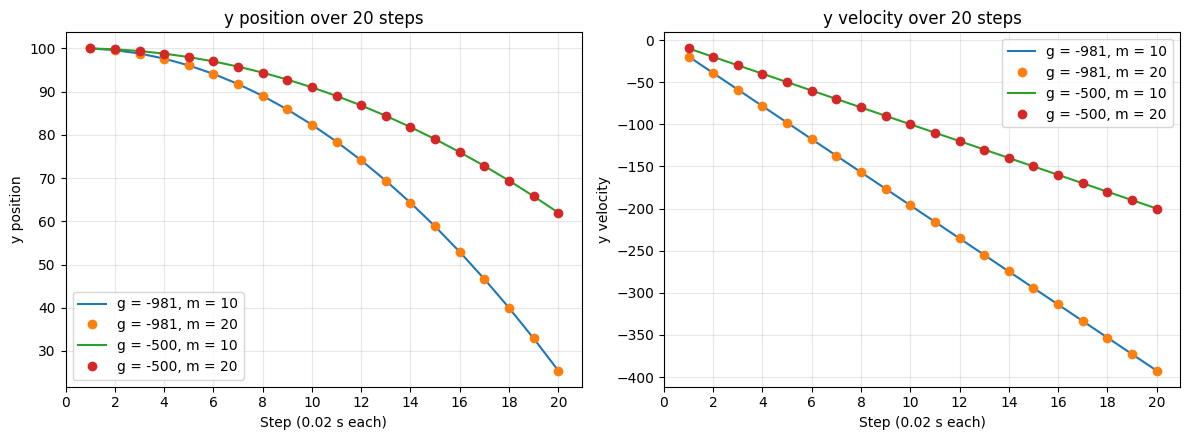

In [9]:
cases = {"g = -981, m = 10": (-981, 10, "-"),
         "g = -981, m = 20": (-981, 20, "o"),
         "g = -500, m = 10": (-500, 10, "-"),
         "g = -500, m = 20": (-500, 20, "o")}

plt.figure(figsize=(12, 4.5))
for name in cases:
    g, m, style = cases[name]
    df = run_box(g, m, 20)

    plt.subplot(1, 2, 1)
    plt.plot(df["Step"], df["y"], style, label=name)

    plt.subplot(1, 2, 2)
    plt.plot(df["Step"], df["Velocity y"], style, label=name)

plt.subplot(1, 2, 1)
plt.title("y position over 20 steps")
plt.xlabel("Step (0.02 s each)")
plt.ylabel("y position")
plt.xticks(range(0, 21, 2))
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.title("y velocity over 20 steps")
plt.xlabel("Step (0.02 s each)")
plt.ylabel("y velocity")
plt.xticks(range(0, 21, 2))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Screenshots/lab7_position_velocity.png", dpi=150)
plt.show()

---
## 7. Lab Exercise

Every case below is run for **20 steps** of 0.02 seconds, which is 0.4 seconds of simulated time.

### Exercise 1
> Change gravity to (0,-500).

**Explanation**

Firstly, the gravity was changed from (0, -981) to (0, -500), while the mass stayed at 10, and both boxes were stepped 20 times. The box with -981 gravity dropped from y = 100 to y = 25.444, while the box with -500 gravity only dropped to y = 62.0. Hence, the box fell 38.0 units instead of 74.556, which is about half, as the gravity was also nearly halved. This is similar to dropping a ball on the Moon, where it falls much slower than on Earth.

In [10]:
g981 = run_box(-981, 10, 20)
g500 = run_box(-500, 10, 20)

print("Distance fallen with g = -981:", round(100 - g981["y"][19], 3))
print("Distance fallen with g = -500:", round(100 - g500["y"][19], 3))

ex1 = pd.DataFrame({"Step": g981["Step"],
                    "y (g = -981)": g981["y"],
                    "y (g = -500)": g500["y"]})
ex1

Distance fallen with g = -981: 74.556
Distance fallen with g = -500: 38.0


,Step,y (g = -981),y (g = -500)
0,1,100.000,100.0
1,2,99.608,99.8
2,3,98.823,99.4
3,4,97.646,98.8
4,5,96.076,98.0
5,6,94.114,97.0
6,7,91.760,95.8
7,8,89.013,94.4
8,9,85.874,92.8
9,10,82.342,91.0


### Exercise 2
> Change mass from 10 to 20.

**Explanation**

Secondly, the mass of the box was changed from 10 to 20 using `box.mass = 20`, while the gravity stayed at (0, -981). After 20 steps, both boxes ended at y = 25.444 with a velocity of -392.4, so doubling the mass changed nothing. This is because a heavier box gets a bigger pull but is also harder to move, whereby the two cancel out. This is similar to dropping a heavy stone and a light stone together, where both land at the same time.

In [11]:
m10 = run_box(-981, 10, 20)
m20 = run_box(-981, 20, 20)

ex2 = pd.DataFrame({"Step": m10["Step"],
                    "y (m = 10)": m10["y"],
                    "y (m = 20)": m20["y"],
                    "Velocity y (m = 10)": m10["Velocity y"],
                    "Velocity y (m = 20)": m20["Velocity y"]})
ex2

,Step,y (m = 10),y (m = 20),Velocity y (m = 10),Velocity y (m = 20)
0,1,100.000,100.000,-19.62,-19.62
1,2,99.608,99.608,-39.24,-39.24
2,3,98.823,98.823,-58.86,-58.86
3,4,97.646,97.646,-78.48,-78.48
4,5,96.076,96.076,-98.10,-98.10
5,6,94.114,94.114,-117.72,-117.72
6,7,91.760,91.760,-137.34,-137.34
7,8,89.013,89.013,-156.96,-156.96
8,9,85.874,85.874,-176.58,-176.58
9,10,82.342,82.342,-196.20,-196.20


### Exercise 3
> Observe the body position after 20 simulation steps.

**Explanation**

Thirdly, all four cases were run for 20 steps, which is 0.4 seconds of simulated time. The two boxes with -981 gravity ended at (50.0, 25.444) and the two with -500 gravity at (50.0, 62.0), whether the mass was 10 or 20. The x position stayed at 50, as there is no sideways gravity. Therefore, only gravity decides how far the box falls, similar to the hammer and feather that were dropped together on the Moon in Apollo 15 and landed at the same time.

In [12]:
rows = []
for g in [-981, -500]:
    for m in [10, 20]:
        df = run_box(g, m, 20)
        rows.append({"Gravity": (0, g),
                     "Mass": m,
                     "Position after 20 steps": (50.0, df["y"][19]),
                     "Distance fallen": round(100 - df["y"][19], 3),
                     "Velocity y": df["Velocity y"][19]})
ex3 = pd.DataFrame(rows)
ex3

,Gravity,Mass,Position after 20 steps,Distance fallen,Velocity y
0,"(0, -981)",10,"(50.0, 25.444)",74.556,-392.4
1,"(0, -981)",20,"(50.0, 25.444)",74.556,-392.4
2,"(0, -500)",10,"(50.0, 62.0)",38.000,-200.0
3,"(0, -500)",20,"(50.0, 62.0)",38.000,-200.0


### Exercise 4
> Explain why the object moves downward.

**Explanation**

Lastly, the box moves downward because the gravity is (0, -981), and the y-axis in Pymunk points up, so a negative value pulls it down. Every `space.step(0.02)` adds 981 x 0.02 = 19.62 to the downward speed, which reaches -392.4 after 20 steps. The box does not move in step 1, as Pymunk moves it before adding speed, but then falls 0.392 units in step 2 and 7.456 in step 20. This is similar to a ball rolling down a slope, getting faster the longer it rolls.

In [13]:
ex4 = run_box(-981, 10, 20)

rows = []
last_y = 100
last_v = 0
for i in range(20):
    y = ex4["y"][i]
    v = ex4["Velocity y"][i]
    rows.append({"Step": i + 1,
                 "Velocity y": v,
                 "Speed added": round(v - last_v, 3),
                 "y": y,
                 "Distance this step": round(last_y - y, 3)})
    last_y = y
    last_v = v
pd.DataFrame(rows)

,Step,Velocity y,Speed added,y,Distance this step
0,1,-19.62,-19.62,100.000,0.000
1,2,-39.24,-19.62,99.608,0.392
2,3,-58.86,-19.62,98.823,0.785
3,4,-78.48,-19.62,97.646,1.177
4,5,-98.10,-19.62,96.076,1.570
5,6,-117.72,-19.62,94.114,1.962
6,7,-137.34,-19.62,91.760,2.354
7,8,-156.96,-19.62,89.013,2.747
8,9,-176.58,-19.62,85.874,3.139
9,10,-196.20,-19.62,82.342,3.532


---
## 8. Viva Questions

**1. What is Pymunk?**

Pymunk is a Python library for 2D physics simulation, which handles gravity, collisions and rigid body motion. In this lab, it was used to drop a 10 x 10 box with a mass of 10 from (50, 100) and track its position at every step.

**2. What is a Space object?**

A Space is the 2D world of the simulation, which holds all the bodies and shapes and applies gravity to them. A body only moves if it is added with `space.add()`, and in this lab the space had a gravity of (0, -981).

**3. Why is gravity negative?**

Gravity is negative because the y-axis in Pymunk points upwards, so a pull towards the ground has to be a negative y value. With (0, -981), the box went down from y = 100 to y = 25.444 after 20 steps, while a positive value would make it go up instead.

**4. What is the purpose of `space.step()`?**

`space.step(dt)` moves the simulation forward by `dt` seconds, and updates the velocity and position of every body in the space. In this lab, `space.step(0.02)` was called 20 times for 0.4 seconds, and each step added 19.62 to the downward speed, which reached -392.4 at the end.

**5. What happens if gravity is zero?**

If gravity is (0, 0), there is no force on the box, so it stays at (50, 100) forever, as it starts with no velocity. It would only move if it was given a starting velocity, and then it would move in a straight line at the same speed, like a ball floating in space.

---
## 9. Summary

### Key Points
- A Pymunk simulation needs a **Space** (the world), a **Body** (what moves) and a **Shape** (its outline and mass)
- Objects must be added with `space.add()`, or the space will not move them
- **Gravity** is set as `(x, y)`, and it is negative because the **y-axis points up**
- `space.step(dt)` moves time forward in fixed steps, so a smaller step is more accurate but needs more steps
- Changing **gravity** changes how fast the box falls (25.444 vs 62.0 after 20 steps), but changing the **mass** does not
- The box **speeds up** as it falls, gaining 19.62 in speed every step with gravity -981

### Connection to Modelling & Simulation

Pymunk is a **continuous, time-stepped** simulation, as opposed to the discrete-event SimPy models in Lab 5 and Lab 6. Instead of jumping between events, it updates every object at a fixed time step, which suits systems like falling, bouncing or colliding objects whose state changes all the time.